# Titanic Survival Prediction

## Project Overview

This project predicts passenger survival on the Titanic using machine learning.

The main objectives are:

- Explore the Titanic passenger dataset
- Handle missing values
- Encode categorical variables
- Engineer meaningful features
- Compare multiple machine learning models
- Optimize model hyperparameters using GridSearchCV
- Evaluate the final model on the Kaggle test set

## Dataset

The dataset is provided by Kaggle's Titanic - Machine Learning from Disaster competition.

The training dataset contains passenger information together with the target variable `Survived`.

The test dataset contains passenger information without the target variable.



### Target

- `Survived = 0`: Did not survive
- `Survived = 1`: Survived

## 1. Import libraries

In [1]:


import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import FunctionTransformer
from sklearn.compose import ColumnTransformer

from sklearn.pipeline import Pipeline
from sklearn.pipeline import make_pipeline

from sklearn.model_selection import cross_val_score
from sklearn.model_selection import GridSearchCV

from sklearn.linear_model import SGDClassifier
from sklearn.linear_model import LogisticRegression

from sklearn.ensemble import RandomForestClassifier

from sklearn.neighbors import KNeighborsClassifier

## 2. Load Dataset

In [2]:
test_data = pd.read_csv("/kaggle/input/competitions/titanic/test.csv")

test_data.head()

train_data = pd.read_csv("/kaggle/input/competitions/titanic/train.csv")

train_data.info()

train_data

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S
...,...,...,...,...,...,...,...,...,...,...,...,...
886,887,0,2,"Montvila, Rev. Juozas",male,27.0,0,0,211536,13.0000,NaN,S
887,888,1,1,"Graham, Miss. Margaret Edith",female,19.0,0,0,112053,30.0000,B42,S
888,889,0,3,"Johnston, Miss. Catherine Helen ""Carrie""",female,NaN,1,2,W./C. 6607,23.4500,NaN,S
889,890,1,1,"Behr, Mr. Karl Howell",male,26.0,0,0,111369,30.0000,C148,C


## 3. Initial Data Inspection

The dataset contains both numerical and categorical variables.

Categorical variables include `Name`, `Sex`, `Ticket`, `Cabin`, and `Embarked`.

Numerical variables include `PassengerId`, `Age`, and `Fare`.

`Name` will not be used in the initial model.

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
PassengerId,1.000000,-0.005007,-0.035144,0.036847,-0.057527,-0.001652,0.012658
Survived,-0.005007,1.000000,-0.338481,-0.077221,-0.035322,0.081629,0.257307
Pclass,-0.035144,-0.338481,1.000000,-0.369226,0.083081,0.018443,-0.549500
Age,0.036847,-0.077221,-0.369226,1.000000,-0.308247,-0.189119,0.096067
SibSp,-0.057527,-0.035322,0.083081,-0.308247,1.000000,0.414838,0.159651
Parch,-0.001652,0.081629,0.018443,-0.189119,0.414838,1.000000,0.216225
Fare,0.012658,0.257307,-0.549500,0.096067,0.159651,0.216225,1.000000


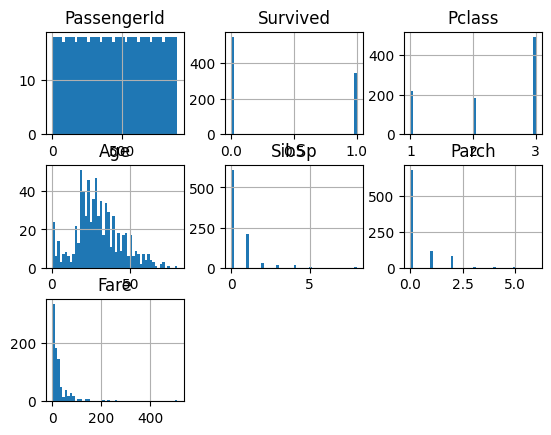

In [3]:
train_data.hist(bins=50)

corr_matrix=train_data.corr(numeric_only=True)
corr_matrix # Pclass and Fare can be good feature for Survived

## 4. Initial Data Preprocessing

In [4]:
X_train=train_data.drop(["Survived","Name"],axis=1)

y_train=train_data['Survived'].copy()

# Name,Sex,Ticket,Cabin,Embarked is object

# Categorical variable
# Name: not needed
# Sex : Imputator(most frequent)-> OneHotEncoder
# Cabin: Imputator(most frequent) -> OneHotEncoder
# Embarked: impuator(most frequent) -> OneHotEncoder
# Pclass: same (str change)
# Parch: same (str change)
# SibSp : same (str change)
# Ticket: train_data["Ticket"] = train_data["Ticket"].astype(str)
# cat_pipeline for that


# Numerical variable
# Passengerid
# Age
# Fare
# num_pipeline: imputator(median)-> Transformation-> Standardization
# Age and Fare is skewed -> log or sqrt

## 5. Initial Preprocessing Pipeline

In [5]:
num_pipeline=make_pipeline(
    SimpleImputer(strategy="median"),
    FunctionTransformer(np.sqrt,feature_names_out="one-to-one"),
    StandardScaler()
)

cat_pipeline=make_pipeline(
    SimpleImputer(strategy="most_frequent"),
    OneHotEncoder(handle_unknown="ignore",sparse_output=False)
)

num_attribs = ['PassengerId', 'Age', 'Fare']

cat_attribs = ['Pclass', 'Sex', 'SibSp',
       'Parch', 'Ticket', 'Cabin', 'Embarked']

preprocessing=ColumnTransformer([
    ("num",num_pipeline,num_attribs),
    ("cat",cat_pipeline,cat_attribs)
])

X_train_prepared=preprocessing.fit_transform(X_train)

X_train_prepared=pd.DataFrame(
    X_train_prepared,
    columns=preprocessing.get_feature_names_out(),
    index=X_train.index
)

X_train_prepared

,num__PassengerId,num__Age,num__Fare,cat__Pclass_1,cat__Pclass_2,cat__Pclass_3,cat__Sex_female,cat__Sex_male,cat__SibSp_0,cat__SibSp_1,...,cat__Cabin_F G73,cat__Cabin_F2,cat__Cabin_F33,cat__Cabin_F38,cat__Cabin_F4,cat__Cabin_G6,cat__Cabin_T,cat__Embarked_C,cat__Embarked_Q,cat__Embarked_S
0,-2.692935,-0.424180,-0.733117,0.0,0.0,1.0,0.0,1.0,0.0,1.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
1,-2.633967,0.686187,1.219822,1.0,0.0,0.0,1.0,0.0,0.0,1.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
2,-2.588719,-0.116378,-0.691495,0.0,0.0,1.0,1.0,0.0,1.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
3,-2.550574,0.499116,0.827232,1.0,0.0,0.0,1.0,0.0,0.0,1.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
4,-2.516967,0.499116,-0.683984,0.0,0.0,1.0,0.0,1.0,1.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
886,1.404571,-0.043207,-0.423054,0.0,1.0,0.0,0.0,1.0,1.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
887,1.406960,-0.673913,0.212604,1.0,0.0,0.0,1.0,0.0,1.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
888,1.409348,0.028620,-0.002955,0.0,0.0,1.0,1.0,0.0,0.0,1.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
889,1.411735,-0.116378,0.212604,1.0,0.0,0.0,0.0,1.0,1.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0


## 6. Baseline Models

Before introducing additional engineered features, I first evaluate several classification models using the original features.

In [6]:
sgd_clf=SGDClassifier(random_state=42)
sgd_clf.fit(X_train_prepared,y_train)

scores_sgd=cross_val_score(
    sgd_clf,
    X_train_prepared,
    y_train,
    cv=3,
    scoring="accuracy"
)

scores_sgd.mean()

np.float64(0.8170594837261503)

In [7]:
log_clf=LogisticRegression(max_iter=10000)

scores_log=cross_val_score(
    log_clf,
    X_train_prepared,
    y_train,
    cv=3,
    scoring="accuracy"
)

scores_log.mean()

np.float64(0.8170594837261506)

In [8]:
forest_clf=RandomForestClassifier(random_state=42)

In [9]:
knn_clf=KNeighborsClassifier()

param_grid=[{'weights':['uniform','distance'],'n_neighbors':[3,4,5]}]

grid_search_knn=GridSearchCV(
    knn_clf,
    param_grid=param_grid,
    cv=3,
    scoring="accuracy"
)

grid_search_knn.fit(X_train_prepared,y_train)

grid_search_knn.best_estimator_

grid_search_knn.best_score_

np.float64(0.8013468013468014)

## 7. Feature Engineering

In [10]:
def add_features(df):
    df = df.copy()

    # Family
    df["FamilySize"] = df["SibSp"] + df["Parch"] + 1
    df["IsAlone"] = (df["FamilySize"] == 1).astype(int)

    # Title
    df["Title"] = df["Name"].str.extract(r",\s*([^.]*)\.")

    # Deck
    df["Deck"] = df["Cabin"].str[0]

    # Ticket group
    ticket_counts = df["Ticket"].value_counts()
    df["TicketGroupSize"] = df["Ticket"].map(ticket_counts)

    # Fare per person
    df["FarePerPerson"] = df["Fare"] / df["TicketGroupSize"]

    return df


train_data=add_features(train_data)
train_data

test_data=add_features(test_data)

## 8. Prepare Training Data Again

In [11]:
X_train = train_data.drop("Survived", axis=1)
y_train = train_data["Survived"].copy()


num_attribs = [
    'PassengerId',
    'Age',
    'Fare',
    'FamilySize',
    'IsAlone',
    'TicketGroupSize',
    'FarePerPerson'
]

cat_attribs = [
    'Pclass',
    'Sex',
    'SibSp',
    'Parch',
    'Ticket',
    'Cabin',
    'Embarked',
    'Title',
    'Deck'
]

preprocessing=ColumnTransformer([
    ("num",num_pipeline,num_attribs),
    ("cat",cat_pipeline,cat_attribs)
])

X_train_prepared=preprocessing.fit_transform(X_train)

X_train_prepared=pd.DataFrame(
    X_train_prepared,
    columns=preprocessing.get_feature_names_out(),
    index=X_train.index
)

X_train_prepared

,num__PassengerId,num__Age,num__Fare,num__FamilySize,num__IsAlone,num__TicketGroupSize,num__FarePerPerson,cat__Pclass_1,cat__Pclass_2,cat__Pclass_3,...,cat__Title_Sir,cat__Title_the Countess,cat__Deck_A,cat__Deck_B,cat__Deck_C,cat__Deck_D,cat__Deck_E,cat__Deck_F,cat__Deck_G,cat__Deck_T
0,-2.692935,-0.424180,-0.733117,0.246232,-1.231645,-0.648923,-0.612430,0.0,0.0,1.0,...,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0
1,-2.633967,0.686187,1.219822,0.246232,-1.231645,-0.648923,2.550924,1.0,0.0,0.0,...,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0
2,-2.588719,-0.116378,-0.691495,-0.650498,0.811922,-0.648923,-0.545010,0.0,0.0,1.0,...,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0
3,-2.550574,0.499116,0.827232,0.246232,-1.231645,0.344814,0.740898,1.0,0.0,0.0,...,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0
4,-2.516967,0.499116,-0.683984,-0.650498,0.811922,-0.648923,-0.532845,0.0,0.0,1.0,...,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
886,1.404571,-0.043207,-0.423054,-0.650498,0.811922,-0.648923,-0.110193,0.0,1.0,0.0,...,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0
887,1.406960,-0.673913,0.212604,-0.650498,0.811922,-0.648923,0.919441,1.0,0.0,0.0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0
888,1.409348,0.028620,-0.002955,1.514400,-1.231645,0.344814,-0.209968,0.0,0.0,1.0,...,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0
889,1.411735,-0.116378,0.212604,-0.650498,0.811922,-0.648923,0.919441,1.0,0.0,0.0,...,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0


## 9. Hyperparameter Tuning

In [12]:
sgd_clf=SGDClassifier(random_state=42)
forest_clf=RandomForestClassifier(random_state=42)


log_grid = {
    "C": [0.01, 0.1, 1, 10, 100]
}

sgd_grid = {
    "loss": ["hinge", "log_loss"],
    "alpha": [0.0001, 0.001, 0.01]
}

forest_grid = {
    "n_estimators": [100, 200],
    "max_depth": [5, 10, None],
    "min_samples_split": [2, 5],
    "max_features": ["sqrt", "log2"]
}

In [13]:
# 9-1. SGD

grid_search_sgd=GridSearchCV(
    sgd_clf,
    param_grid=sgd_grid,
    cv=3,
    scoring="accuracy"
)

grid_search_sgd.fit(X_train_prepared,y_train)

grid_search_sgd.best_estimator_

print(grid_search_sgd.best_score_)

0.8260381593714928


In [14]:
# 9-2. Logistic Regression

grid_search_log=GridSearchCV(
    log_clf,
    param_grid=log_grid,
    cv=3,
    scoring="accuracy"
)

grid_search_log.fit(X_train_prepared,y_train)

grid_search_log.best_estimator_

print(grid_search_log.best_score_)


0.8350168350168351


In [15]:
# 9-3. Random Forest

grid_search_rf=GridSearchCV(
    forest_clf,
    param_grid=forest_grid,
    cv=3,
    scoring="accuracy"
)

grid_search_rf.fit(X_train_prepared,y_train)

print(grid_search_rf.best_score_)


0.8338945005611672


In [16]:
# 9-4. KNN

from sklearn.neighbors import KNeighborsClassifier

knn_clf=KNeighborsClassifier()

param_grid=[{'weights':['uniform','distance'],'n_neighbors':[3,4,5]}]

grid_search_knn=GridSearchCV(knn_clf,param_grid=param_grid,cv=3,scoring="accuracy")

grid_search_knn.fit(X_train_prepared,y_train)

grid_search_knn.best_estimator_

print(grid_search_knn.best_score_)



0.8181818181818182


## 10. Final Model

Logistic Regression had the most high accuracy score with 83 % out of 4 Models

## 11. Test Data Preprocessing

In [17]:
X_test=test_data
X_test_prepared=preprocessing.transform(X_test) # should not use fit_transform()
                                                # since we already fit preprocessing estimator with train data
X_test_prepared=pd.DataFrame(
    X_test_prepared,
    columns=preprocessing.get_feature_names_out(),
    index=X_test.index
)

X_test_prepared

,num__PassengerId,num__Age,num__Fare,num__FamilySize,num__IsAlone,num__TicketGroupSize,num__FarePerPerson,cat__Pclass_1,cat__Pclass_2,cat__Pclass_3,...,cat__Title_Sir,cat__Title_the Countess,cat__Deck_A,cat__Deck_B,cat__Deck_C,cat__Deck_D,cat__Deck_E,cat__Deck_F,cat__Deck_G,cat__Deck_T
0,1.416504,0.467169,-0.697291,-0.650498,0.811922,-0.648923,-0.554399,0.0,0.0,1.0,...,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0
1,1.418887,1.206901,-0.749022,0.246232,-1.231645,-0.648923,-0.638192,0.0,0.0,1.0,...,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0
2,1.421268,1.974030,-0.590513,-0.650498,0.811922,-0.648923,-0.381441,0.0,1.0,0.0,...,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0
3,1.423648,-0.043207,-0.647998,-0.650498,0.811922,-0.648923,-0.474554,0.0,0.0,1.0,...,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0
4,1.426027,-0.424180,-0.457083,0.934317,-1.231645,-0.648923,-0.165313,0.0,0.0,1.0,...,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
413,2.307457,0.028620,-0.683984,-0.650498,0.811922,-0.648923,-0.532845,0.0,0.0,1.0,...,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0
414,2.309427,0.746892,1.896540,-0.650498,0.811922,-0.648923,3.647066,1.0,0.0,0.0,...,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0
415,2.311396,0.716638,-0.733117,-0.650498,0.811922,-0.648923,-0.612430,0.0,0.0,1.0,...,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0
416,2.313365,0.028620,-0.683984,-0.650498,0.811922,-0.648923,-0.532845,0.0,0.0,1.0,...,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0


## 12. Prediction

In [18]:
y_test=grid_search_log.best_estimator_.predict(X_test_prepared)

y_test

array([0, 1, 0, 0, 1, 0, 1, 0, 1, 0, 0, 0, 1, 0, 1, 1, 0, 0, 1, 1, 0, 1,
       1, 0, 1, 0, 1, 0, 0, 0, 0, 0, 1, 0, 0, 0, 1, 1, 0, 1, 0, 1, 0, 1,
       1, 0, 0, 0, 1, 1, 0, 0, 1, 1, 0, 0, 0, 0, 0, 1, 0, 0, 0, 1, 1, 1,
       1, 0, 0, 1, 1, 0, 1, 1, 1, 0, 0, 1, 0, 1, 0, 0, 0, 0, 0, 0, 1, 1,
       1, 1, 1, 0, 1, 0, 0, 0, 1, 0, 1, 0, 1, 0, 0, 0, 1, 0, 0, 0, 0, 0,
       0, 1, 1, 1, 1, 0, 0, 1, 0, 1, 1, 0, 1, 0, 0, 1, 0, 1, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 1, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 1,
       1, 0, 1, 1, 0, 1, 1, 1, 1, 0, 0, 1, 0, 0, 1, 1, 0, 0, 0, 0, 0, 1,
       1, 0, 1, 1, 0, 1, 1, 0, 1, 0, 1, 0, 0, 0, 0, 0, 1, 0, 1, 0, 1, 1,
       0, 1, 1, 1, 0, 1, 0, 0, 1, 0, 1, 0, 0, 0, 0, 1, 0, 0, 1, 0, 1, 0,
       1, 0, 1, 0, 1, 1, 0, 1, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 1, 1, 1, 1,
       1, 0, 0, 0, 1, 0, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 1, 1,
       0, 0, 0, 0, 1, 0, 0, 0, 1, 1, 0, 1, 0, 0, 0, 0, 1, 1, 1, 1, 0, 0,
       0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 1, 0, 0, 0, 0,

## 13. Submission File

In [19]:
submission=pd.DataFrame({
    'PassengerId':test_data['PassengerId'],
    'Survived':y_test
})

submission.head()
submission.to_csv("submission.csv", index=False)
submission.shape


(418, 2)